# Análise de Dados: Turnover de Funcionários
O setor de Recursos Humanos de uma empresa fictícia do ramo de tecnologia identificou a necessidade de compreender os fatores associados à rotatividade (turnover) de seus colaboradores.

O objetivo desta análise é investigar os dados dos funcionários, identificar padrões relacionados aos desligamentos e compreender quais características e fatores organizacionais podem estar associados à saída de colaboradores.

Por meio de técnicas de análise exploratória de dados e métodos estatísticos, busca-se gerar informações relevantes para apoiar a tomada de decisão e propor melhorias nas políticas de Recursos Humanos, visando à redução do turnover e ao aumento da retenção de talentos.

In [1]:
# Importa a biblioteca pandas, utilizada para manipulação e análise de dados
import pandas as pd

# Importa a biblioteca NumPy, utilizada para cálculos numéricos,
# operações matemáticas e tratamento de valores especiais, como infinito
import numpy as np

In [2]:
# Lê o arquivo CSV chamado 'base_rh.csv' e carrega os dados em um DataFrame.
# O parâmetro sep=";" informa que as colunas do arquivo são separadas por ponto e vírgula.
df = pd.read_csv('base_rh.csv', sep=";")

# Exibe as 5 primeiras linhas do DataFrame para visualizar os dados carregados.
df.head(5)

,ID,Funcionário_deixou_a_empresa,Idade,Frequência de Viagens,Distância_do_trabalho,Formação,E-Sat,Gênero,Estado_Civil,Salário,...,Faz_hora_extras?,Perc_de_aumento,Qte_ações_da_empresa,Tempo_de_carreira,Horas_de_treinamento,Equilibrio_de_Vida,Tempo_de_empresa,Anos_no_mesmo_cargo,Anos_desde_a_ultima_promocao,Anos_com_o_mesmo_chefe
0,1,Sim,41,Viaja raramente,1,Ensino Técnico,Médio,M,Solteiro,5993,...,Sim,11,0,8,0,Ruim,6,4,0,5
1,2,Não,49,Viaja frequentemente,8,Ensino Médio,Alto,H,Casado,5130,...,Não,23,1,10,3,Muito bom,10,7,1,7
2,3,Sim,37,Viaja raramente,2,Ensino Técnico,Muito Alto,H,Solteiro,2090,...,Sim,15,0,7,3,Muito bom,0,0,0,0
3,4,Não,33,Viaja frequentemente,3,Mestrado,Muito Alto,M,Casado,2909,...,Sim,11,0,8,3,Muito bom,8,7,3,0
4,5,Não,27,Viaja raramente,2,Ensino Médio,Baixo,H,Casado,3468,...,Não,12,1,6,3,Muito bom,2,2,2,2


## Análise Exploratória dos dados (EDA)

In [3]:
# Retorna as dimensões do DataFrame, informando a quantidade de linhas e colunas.
# O resultado é uma tupla no formato (número de linhas, número de colunas).
df.shape

(1470, 21)

In [4]:
# Exibe o tipo de dado de cada coluna do DataFrame.
# Permite identificar se as variáveis são numéricas (int64, float64),
# textuais (object), booleanas (bool) ou de outros tipos.
df.dtypes

ID                               int64
Funcionário_deixou_a_empresa    object
Idade                            int64
Frequência de Viagens           object
Distância_do_trabalho            int64
Formação                        object
E-Sat                           object
Gênero                          object
Estado_Civil                    object
Salário                          int64
Qte_Empresas_Trabalhadas         int64
Faz_hora_extras?                object
Perc_de_aumento                  int64
Qte_ações_da_empresa             int64
Tempo_de_carreira                int64
Horas_de_treinamento             int64
Equilibrio_de_Vida              object
Tempo_de_empresa                 int64
Anos_no_mesmo_cargo              int64
Anos_desde_a_ultima_promocao     int64
Anos_com_o_mesmo_chefe           int64
dtype: object

In [ ]:
# Verifica a quantidade de valores ausentes (missing) em cada coluna do DataFrame.
# 0 = não existe dados ausentes na coluna
df.isnull().sum()

ID                              0
Funcionário_deixou_a_empresa    0
Idade                           0
Frequência de Viagens           0
Distância_do_trabalho           0
Formação                        0
E-Sat                           0
Gênero                          0
Estado_Civil                    0
Salário                         0
Qte_Empresas_Trabalhadas        0
Faz_hora_extras?                0
Perc_de_aumento                 0
Qte_ações_da_empresa            0
Tempo_de_carreira               0
Horas_de_treinamento            0
Equilibrio_de_Vida              0
Tempo_de_empresa                0
Anos_no_mesmo_cargo             0
Anos_desde_a_ultima_promocao    0
Anos_com_o_mesmo_chefe          0
dtype: int64

In [7]:
# Verifica se existem IDs duplicados na tabela
# True = existem dados duplicados
# False = não existem dados duplicados
df['ID'].duplicated().any()

False

#### Medidas resumo para compreender melhor as variáves numéricas.

In [ ]:
# Gera estatísticas descritivas do DataFrame, transpõe a tabela
# e seleciona as linhas e colunas a partir do segundo índice.
df.describe().T.iloc[1:,1:]

,mean,std,min,25%,50%,75%,max
Idade,36.923810,9.135373,18.0,30.0,36.0,43.0,60.0
Distância_do_trabalho,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Salário,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.0,19999.0
Qte_Empresas_Trabalhadas,2.693197,2.498009,0.0,1.0,2.0,4.0,9.0
Perc_de_aumento,15.209524,3.659938,11.0,12.0,14.0,18.0,25.0
Qte_ações_da_empresa,0.793878,0.852077,0.0,0.0,1.0,1.0,3.0
Tempo_de_carreira,11.279592,7.780782,0.0,6.0,10.0,15.0,40.0
Horas_de_treinamento,2.799320,1.289271,0.0,2.0,3.0,3.0,6.0
Tempo_de_empresa,7.008163,6.126525,0.0,3.0,5.0,9.0,40.0
Anos_no_mesmo_cargo,4.229252,3.623137,0.0,2.0,3.0,7.0,18.0


In [ ]:
# Gera estatísticas descritivas do DataFrame e seleciona
# as linhas e colunas a partir da segunda posição.
df.describe().iloc[1:,1:]

,Idade,Distância_do_trabalho,Salário,Qte_Empresas_Trabalhadas,Perc_de_aumento,Qte_ações_da_empresa,Tempo_de_carreira,Horas_de_treinamento,Tempo_de_empresa,Anos_no_mesmo_cargo,Anos_desde_a_ultima_promocao,Anos_com_o_mesmo_chefe
mean,36.923810,9.192517,6502.931293,2.693197,15.209524,0.793878,11.279592,2.799320,7.008163,4.229252,2.187755,4.123129
std,9.135373,8.106864,4707.956783,2.498009,3.659938,0.852077,7.780782,1.289271,6.126525,3.623137,3.222430,3.568136
min,18.000000,1.000000,1009.000000,0.000000,11.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,2.000000,2911.000000,1.000000,12.000000,0.000000,6.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,7.000000,4919.000000,2.000000,14.000000,1.000000,10.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,14.000000,8379.000000,4.000000,18.000000,1.000000,15.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,29.000000,19999.000000,9.000000,25.000000,3.000000,40.000000,6.000000,40.000000,18.000000,15.000000,17.000000


## Tabelas de frequência (com frequências absolutas e relativas).

### Dados das variaveis categóricas

In [9]:
# Variaveis Categóricas
# filtra apenas as colunas do tipo "object" (ou seja, colunas string)
df2 = df.loc[ : ,  df.dtypes == 'object']
df2.head(10)

,Funcionário_deixou_a_empresa,Frequência de Viagens,Formação,E-Sat,Gênero,Estado_Civil,Faz_hora_extras?,Equilibrio_de_Vida
0,Sim,Viaja raramente,Ensino Técnico,Médio,M,Solteiro,Sim,Ruim
1,Não,Viaja frequentemente,Ensino Médio,Alto,H,Casado,Não,Muito bom
2,Sim,Viaja raramente,Ensino Técnico,Muito Alto,H,Solteiro,Sim,Muito bom
3,Não,Viaja frequentemente,Mestrado,Muito Alto,M,Casado,Sim,Muito bom
4,Não,Viaja raramente,Ensino Médio,Baixo,H,Casado,Não,Muito bom
5,Não,Viaja frequentemente,Ensino Técnico,Muito Alto,H,Solteiro,Não,Bom
6,Não,Viaja raramente,Ensino Superior,Alto,M,Casado,Sim,Bom
7,Não,Viaja raramente,Ensino Médio,Muito Alto,H,Divorciado,Não,Muito bom
8,Não,Viaja frequentemente,Ensino Superior,Muito Alto,H,Solteiro,Não,Muito bom
9,Não,Viaja raramente,Ensino Superior,Alto,H,Casado,Não,Bom


In [20]:

# Importa a função display, do módulo IPython.display, para exibir
# múltiplos DataFrames ou tabelas formatadas no Jupyter Notebook ou Google Colab.
from IPython.display import display


# Define uma função para calcular e exibir as frequências de uma variável.
# Parâmetros:
# df  = DataFrame que contém os dados.
# var = nome da coluna que será analisada.
def frequencias(df, var, ordem=None):

    # Conta a frequência absoluta de cada categoria, incluindo valores ausentes
    freq_abs = df[var].value_counts(
        sort=False,
        dropna=False
    )

    # Se houver uma ordem de categorias definida, organiza a tabela nessa ordem
    if ordem is not None:
        categorias = list(ordem)

        # Acrescenta categorias ausentes dos dados, se existirem
        categorias_extra = [
            categoria for categoria in freq_abs.index
            if categoria not in categorias
            and not pd.isna(categoria)
        ]

        categorias = categorias + categorias_extra

        # Reorganiza as frequências de acordo com a ordem informada
        freq_abs = freq_abs.reindex(categorias, fill_value=0)

        # Acrescenta os valores ausentes, caso existam
        if df[var].isna().any():
            freq_abs.loc['Não informado'] = df[var].isna().sum()

    # Monta a tabela de frequências
    df3 = pd.DataFrame({
        'Freq. Absoluta': freq_abs
    })

    # Calcula a frequência relativa percentual
    # usando o total de linhas do DataFrame
    df3['Freq. Relativa (%)'] = (
        df3['Freq. Absoluta'] / len(df) * 100
    ).round(2)

    # Dá um nome ao índice que contém as categorias
    df3.index.name = var

    # Exibe a tabela formatada
    display(df3)

    # Retorna a tabela para que possa ser utilizada em outras operações
    return df3

In [21]:
# Percorre todas as colunas do DataFrame df2 (variaveis categoricas)
for coluna in df2.columns:

    # Exibe o nome da coluna que está sendo analisada
    print(coluna)

    # Chama a função frequencias() para calcular e exibir
    # a frequência absoluta e a frequência relativa dos valores existentes na coluna atual
    frequencias(df2, coluna)

Funcionário_deixou_a_empresa


,Freq. Absoluta,Freq. Relativa (%)
Funcionário_deixou_a_empresa,,
Sim,237,16.12
Não,1233,83.88


Frequência de Viagens


,Freq. Absoluta,Freq. Relativa (%)
Frequência de Viagens,,
Não viaja,150,10.20
Viaja raramente,1043,70.95
Viaja frequentemente,277,18.84


Formação


...

,Freq. Absoluta,Freq. Relativa (%)
Estado_Civil,,
Divorciado,327,22.24
Casado,673,45.78
Solteiro,470,31.97


Faz_hora_extras?


,Freq. Absoluta,Freq. Relativa (%)
Faz_hora_extras?,,
Sim,416,28.3
Não,1054,71.7


Equilibrio_de_Vida


,Freq. Absoluta,Freq. Relativa (%)
Equilibrio_de_Vida,,
Muito bom,893,60.75
Excelente,153,10.41
Ruim,80,5.44
Bom,344,23.40


### Dados de variaveis numéricas

In [22]:
# Variaveis Numéricas
# filtra apenas as colunas do tipo "int64" (ou seja, colunas numéricas)
df4 = df.loc[ : ,  df.dtypes == 'int64']
df4.head(10)

,ID,Idade,Distância_do_trabalho,Salário,Qte_Empresas_Trabalhadas,Perc_de_aumento,Qte_ações_da_empresa,Tempo_de_carreira,Horas_de_treinamento,Tempo_de_empresa,Anos_no_mesmo_cargo,Anos_desde_a_ultima_promocao,Anos_com_o_mesmo_chefe
0,1,41,1,5993,8,11,0,8,0,6,4,0,5
1,2,49,8,5130,1,23,1,10,3,10,7,1,7
2,3,37,2,2090,6,15,0,7,3,0,0,0,0
3,4,33,3,2909,1,11,0,8,3,8,7,3,0
4,5,27,2,3468,9,12,1,6,3,2,2,2,2
5,6,32,2,3068,0,13,0,8,2,7,7,3,6
6,7,59,3,2670,4,20,3,12,3,1,0,0,0
7,8,30,24,2693,1,22,1,1,2,1,0,0,0
8,9,38,23,9526,0,21,0,10,2,9,7,1,8
9,10,36,27,5237,6,13,2,17,3,7,7,7,7


### Criando faixas para as variaveis numéricas
- Criamos faixas para variáveis numéricas para facilitar a análise e a interpretação dos dados, principalmente quando trabalhamos com grandes volumes de informações.
- Em vez de analisar cada valor numérico individualmente, agrupamos os valores em intervalos que representam categorias. 
- Essa técnica é chamada de discretização de variáveis numéricas.

In [23]:
# Configuração das faixas de cada variável numérica
faixas_variaveis = {
    'Idade': {
        'bins': [-np.inf, 25, 30, 35, 40, 45, 51, np.inf],
        'labels': ['<25', '25-29', '30-34', '35-39',
                   '40-44', '45-50', '>50']
    },

    'Salário': {
        'bins': [-np.inf, 2500, 3500, 4500, 5500, 6500,
                 7500, 8500, 9500, 10500, 11500, np.inf],
        'labels': ['<2500', '2500-3499', '3500-4499',
                   '4500-5499', '5500-6499', '6500-7499',
                   '7500-8499', '8500-9499', '9500-10499',
                   '10500-11499', '>11500']
    },

    'Distância_do_trabalho': {
        'bins': [-np.inf, 2.5, 7.5, 12.5, np.inf],
        'labels': ['<2,5', '2,5-7,5', '7,5-12,5', '>12,5']
    },

    'Qte_Empresas_Trabalhadas': {
        'bins': [-np.inf, 1, 3, 5, np.inf],
        'labels': ['<1', '1-2', '3-4', '>5']
    },

    'Perc_de_aumento': {
        'bins': [-np.inf, 12, 14, 16, 19, np.inf],
        'labels': ['<12', '12-13', '14-15', '16-18', '>18']
    },

    'Qte_ações_da_empresa': {
    'bins': [-np.inf, 1, 4],
    'labels': ['<1', '1-3']
    },

    'Tempo_de_carreira': {
        'bins': [-np.inf, 3, 6, 9, 12, 15, 18, 21,
                 24, 27, np.inf],
        'labels': ['0-2', '3-5', '6-8', '9-11', '12-14',
                   '15-17', '18-20', '21-23', '24-26', '>27']
    },

    'Horas_de_treinamento': {
    'bins': [-np.inf, 3, 5, 7],
    'labels': ['<3', '3-4', '5-6']
    },

    'Tempo_de_empresa': {
        'bins': [-np.inf, 3, 6, 9, 13, np.inf],
        'labels': ['0-2', '3-5', '6-8', '9-12', '>12']
    },

    'Anos_no_mesmo_cargo': {
        'bins': [-np.inf, 2, 4, 6, 8, 10, np.inf],
        'labels': ['0-1', '2-3', '4-5', '6-7', '8-9', '>10']
    },

    'Anos_desde_a_ultima_promocao': {
        'bins': [-np.inf, 1, 4, np.inf],
        'labels': ['<1', '1-3', '>3']
    },

    'Anos_com_o_mesmo_chefe': {
        'bins': [-np.inf, 2, 4, 6, 8, 10, np.inf],
        'labels': ['0-1', '2-3', '4-5', '6-7', '8-9', '>10']
    }
}

# Cria as faixas no DataFrame original
for coluna, config in faixas_variaveis.items():

    df[f'Faixa_{coluna}'] = pd.cut(
        df[coluna],
        bins=config['bins'],
        labels=config['labels'],
        right=False
    )

# Visualiza as novas colunas
colunas_faixas = [
    f'Faixa_{coluna}' for coluna in faixas_variaveis
]

df[colunas_faixas].head()

,Faixa_Idade,Faixa_Salário,Faixa_Distância_do_trabalho,Faixa_Qte_Empresas_Trabalhadas,Faixa_Perc_de_aumento,Faixa_Qte_ações_da_empresa,Faixa_Tempo_de_carreira,Faixa_Horas_de_treinamento,Faixa_Tempo_de_empresa,Faixa_Anos_no_mesmo_cargo,Faixa_Anos_desde_a_ultima_promocao,Faixa_Anos_com_o_mesmo_chefe
0,40-44,5500-6499,"<2,5",>5,<12,<1,6-8,<3,6-8,4-5,<1,4-5
1,45-50,4500-5499,"7,5-12,5",1-2,>18,1-3,9-11,3-4,9-12,6-7,1-3,6-7
2,35-39,<2500,"<2,5",>5,14-15,<1,6-8,3-4,0-2,0-1,<1,0-1
3,30-34,2500-3499,"2,5-7,5",1-2,<12,<1,6-8,3-4,6-8,6-7,1-3,0-1
4,25-29,2500-3499,"<2,5",>5,12-13,1-3,6-8,3-4,0-2,2-3,1-3,2-3


In [24]:
# Lista para armazenar as tabelas de frequências das faixas
tabelas_frequencias_faixas = []

# Percorre as variáveis numéricas definidas no dicionário de faixas
for coluna, config in faixas_variaveis.items():

    # Nome da coluna que contém as faixas criadas
    nome_faixa = f'Faixa_{coluna}'

    print(f'Frequência da variável: {nome_faixa}')

    # Calcula as frequências respeitando a ordem das faixas
    tabela = frequencias(
        df,
        nome_faixa,
        ordem=config['labels']
    )

    # Adiciona o nome da variável original à tabela
    tabela = tabela.reset_index()
    tabela.insert(0, 'Variável original', coluna)

    # Armazena a tabela para consolidar depois
    tabelas_frequencias_faixas.append(tabela)

Frequência da variável: Faixa_Idade


,Freq. Absoluta,Freq. Relativa (%)
Faixa_Idade,,
<25,97,6.60
25-29,229,15.58
30-34,325,22.11
35-39,297,20.20
40-44,208,14.15
45-50,171,11.63
>50,143,9.73


Frequência da variável: Faixa_Salário


,Freq. Absoluta,Freq. Relativa (%)
Faixa_Salário,,
<2500,224,15.24
2500-3499,248,16.87
3500-4499,177,12.04
4500-5499,204,13.88
5500-6499,121,8.23
6500-7499,85,5.78
7500-8499,51,3.47
8500-9499,42,2.86
9500-10499,70,4.76


Frequência da variável: Faixa_Distância_do_trabalho


...

,Freq. Absoluta,Freq. Relativa (%)
Faixa_Anos_no_mesmo_cargo,,
0-1,301,20.48
2-3,507,34.49
4-5,140,9.52
6-7,259,17.62
8-9,156,10.61
>10,107,7.28


Frequência da variável: Faixa_Anos_desde_a_ultima_promocao


,Freq. Absoluta,Freq. Relativa (%)
Faixa_Anos_desde_a_ultima_promocao,,
<1,581,39.52
1-3,568,38.64
>3,321,21.84


Frequência da variável: Faixa_Anos_com_o_mesmo_chefe


,Freq. Absoluta,Freq. Relativa (%)
Faixa_Anos_com_o_mesmo_chefe,,
0-1,339,23.06
2-3,486,33.06
4-5,129,8.78
6-7,245,16.67
8-9,171,11.63
>10,100,6.80


## Análise de Correlação de Pearson e Information Value (IV)
Nesta etapa da análise exploratória de dados, serão utilizadas duas técnicas estatísticas — Correlação Linear de Pearson e Information Value (IV) — com o objetivo de investigar a relação entre as variáveis disponíveis no conjunto de dados e o turnover dos funcionários, ou seja, o desligamento de colaboradores da empresa.  

A aplicação dessas técnicas permite identificar associações relevantes, compreender melhor os fatores relacionados à rotatividade e apoiar a seleção de variáveis para análises posteriores e possíveis modelos preditivos.

## 1. Matriz de Correlação linear de Pearson com a variáveis numéricas.
Nesta análise, a técnica será utilizada para investigar relações lineares entre as variáveis numéricas do conjunto de dados, contribuindo para a identificação de padrões, associações entre características dos funcionários e possíveis redundâncias entre variáveis.  
- Correlação positiva (próxima de +1): quando uma variável aumenta, a outra tende a aumentar também.

- Correlação negativa (próxima de −1): quando uma variável aumenta, a outra tende a diminuir.

- Correlação próxima de zero: indica pouca ou nenhuma relação linear, embora possa existir uma relação não linear.

In [25]:
# Filtra o DataFrame original para selecionar apenas as colunas
# cujo tipo de dado é int64, ou seja, variáveis numéricas inteiras.
df4 = df.loc[:, df.dtypes == 'int64']

# Remove a coluna "ID", pois ela representa um identificador
# e não deve ser utilizada no cálculo da correlação entre variáveis.
# O parâmetro axis=1 indica que estamos removendo uma coluna.
# Em seguida, calcula a matriz de correlação entre as variáveis restantes.
matriz_correlacao = df4.drop("ID", axis=1).corr()

# Exibe a matriz de correlação, que mostra a intensidade e a direção
# da relação linear entre cada par de variáveis numéricas.
matriz_correlacao

,Idade,Distância_do_trabalho,Salário,Qte_Empresas_Trabalhadas,Perc_de_aumento,Qte_ações_da_empresa,Tempo_de_carreira,Horas_de_treinamento,Tempo_de_empresa,Anos_no_mesmo_cargo,Anos_desde_a_ultima_promocao,Anos_com_o_mesmo_chefe
Idade,1.000000,-0.001686,0.497855,0.299635,0.003634,0.037510,0.680381,-0.019621,0.311309,0.212901,0.216513,0.202089
Distância_do_trabalho,-0.001686,1.000000,-0.017014,-0.029251,0.040235,0.044872,0.004628,-0.036942,0.009508,0.018845,0.010029,0.014406
Salário,0.497855,-0.017014,1.000000,0.149515,-0.027269,0.005408,0.772893,-0.021736,0.514285,0.363818,0.344978,0.344079
Qte_Empresas_Trabalhadas,0.299635,-0.029251,0.149515,1.000000,-0.010238,0.030075,0.237639,-0.066054,-0.118421,-0.090754,-0.036814,-0.110319
Perc_de_aumento,0.003634,0.040235,-0.027269,-0.010238,1.000000,0.007528,-0.020608,-0.005221,-0.035991,-0.001520,-0.022154,-0.011985
Qte_ações_da_empresa,0.037510,0.044872,0.005408,0.030075,0.007528,1.000000,0.010136,0.011274,0.015058,0.050818,0.014352,0.024698
Tempo_de_carreira,0.680381,0.004628,0.772893,0.237639,-0.020608,0.010136,1.000000,-0.035662,0.628133,0.460365,0.404858,0.459188
Horas_de_treinamento,-0.019621,-0.036942,-0.021736,-0.066054,-0.005221,0.011274,-0.035662,1.000000,0.003569,-0.005738,-0.002067,-0.004096
Tempo_de_empresa,0.311309,0.009508,0.514285,-0.118421,-0.035991,0.015058,0.628133,0.003569,1.000000,0.758754,0.618409,0.769212
Anos_no_mesmo_cargo,0.212901,0.018845,0.363818,-0.090754,-0.001520,0.050818,0.460365,-0.005738,0.758754,1.000000,0.548056,0.714365


### 1.1 Gráfico com a Matriz de Correlação

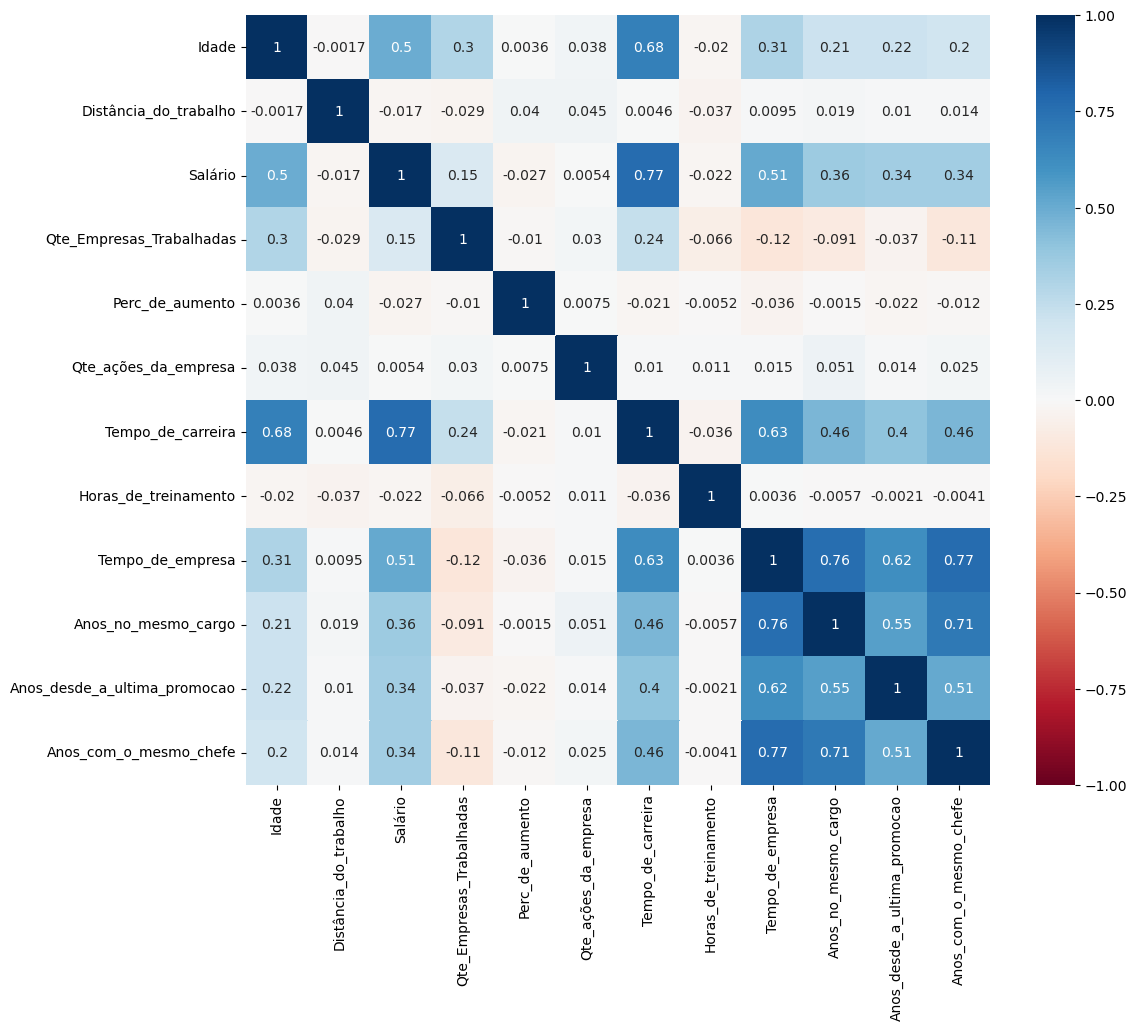

In [26]:
# Melhora a aparência visual da matriz de correlação,
# utilizando as bibliotecas Seaborn e Matplotlib.

# Importa a biblioteca Seaborn, utilizada para criar gráficos estatísticos.
import seaborn as sns

# Importa o módulo Pyplot, da biblioteca Matplotlib,
# utilizado para configurar e exibir gráficos.
import matplotlib.pyplot as plt

# Define o tamanho da figura:
# 12 polegadas de largura e 10 polegadas de altura.
plt.figure(figsize=(12, 10))

# Cria um mapa de calor (heatmap) para visualizar a matriz de correlação.
sns.heatmap(
    matriz_correlacao,  # Matriz de correlação calculada anteriormente.
    cmap='RdBu',        # Define a escala de cores: vermelho, branco e azul.
    annot=True,         # Exibe o valor numérico da correlação em cada célula.
    vmin=-1,            # Define -1 como o limite mínimo da escala de cores.
    vmax=1              # Define +1 como o limite máximo da escala de cores.
);

# O gráfico facilita a identificação visual da intensidade e da direção
# das correlações entre as variáveis numéricas.

### 1.2 Tabela com o resultado da Correlação

In [29]:
# Transforma a matriz de correlação em uma tabela de pares de variáveis
correlacoes = matriz_correlacao.unstack().reset_index()

# Renomeia as colunas
correlacoes.columns = ['Variavel_1', 'Variavel_2', 'Correlacao']

# Remove as correlações da variável com ela mesma (ex.: Idade x Idade = 1)
correlacoes = correlacoes[
    correlacoes['Variavel_1'] != correlacoes['Variavel_2']
]

# Remove pares duplicados (ex.: Idade x Salário e Salário x Idade)
correlacoes['Par'] = correlacoes.apply(
    lambda linha: tuple(sorted([
        linha['Variavel_1'], linha['Variavel_2']
    ])),
    axis=1
)

correlacoes = correlacoes.drop_duplicates(subset='Par').drop(
    columns='Par'
)

# Arredonda os valores para três casas decimais
correlacoes['Correlacao'] = correlacoes['Correlacao'].round(3)

# Ordena pela força da correlação, independentemente do sinal
correlacoes = correlacoes.loc[
    correlacoes['Correlacao'].abs().sort_values(ascending=False).index
].reset_index(drop=True)


print("Correlação entre a Variavel_1 e aVariavel_2")

# Exibe a tabela final
display(correlacoes)

Correlação entre a Variavel_1 e aVariavel_2


,Variavel_1,Variavel_2,Correlacao
0,Salário,Tempo_de_carreira,0.773
1,Tempo_de_empresa,Anos_com_o_mesmo_chefe,0.769
2,Tempo_de_empresa,Anos_no_mesmo_cargo,0.759
3,Anos_no_mesmo_cargo,Anos_com_o_mesmo_chefe,0.714
4,Idade,Tempo_de_carreira,0.680
...,...,...,...
61,Horas_de_treinamento,Tempo_de_empresa,0.004
62,Horas_de_treinamento,Anos_com_o_mesmo_chefe,-0.004
63,Horas_de_treinamento,Anos_desde_a_ultima_promocao,-0.002
64,Perc_de_aumento,Anos_no_mesmo_cargo,-0.002


### 1.3 Tabelas com as Correlações mais relevantes 
Traz apenas resultados com valor absoluto maior que 0,50

In [28]:
# Filtra correlações positivas ou negativas com valor absoluto >= 0,50
correlacoes_relevantes = correlacoes[
    correlacoes['Correlacao'].abs() >= 0.50
]

display(correlacoes_relevantes)

,Variavel_1,Variavel_2,Correlacao
0,Salário,Tempo_de_carreira,0.773
1,Tempo_de_empresa,Anos_com_o_mesmo_chefe,0.769
2,Tempo_de_empresa,Anos_no_mesmo_cargo,0.759
3,Anos_no_mesmo_cargo,Anos_com_o_mesmo_chefe,0.714
4,Idade,Tempo_de_carreira,0.680
5,Tempo_de_carreira,Tempo_de_empresa,0.628
6,Tempo_de_empresa,Anos_desde_a_ultima_promocao,0.618
7,Anos_no_mesmo_cargo,Anos_desde_a_ultima_promocao,0.548
8,Salário,Tempo_de_empresa,0.514
9,Anos_desde_a_ultima_promocao,Anos_com_o_mesmo_chefe,0.510


## 2. Information Value (IV)
O Information Value (IV) é uma métrica utilizada para avaliar o poder discriminatório de uma variável em relação a uma variável-alvo binária. Neste estudo, a variável-alvo representa o desligamento ou a permanência do funcionário na empresa.

| Valor do IV | Interpretação |
|---|---|
| IV menor que 0,02 | Poder preditivo muito baixo |
| IV de 0,02 a 0,099 | Poder preditivo fraco |
| IV de 0,10 a 0,299 | Poder preditivo médio |
| IV de 0,30 a 0,499 | Poder preditivo forte |
| IV igual ou superior a 0,50 | Poder preditivo suspeitosamente alto |

### 2.1 Função que calcule o IV de uma variável categórica.

In [30]:
def analise_iv(df, target, var_escolhida):

    # Cria uma tabela de frequência cruzada entre a variável analisada e o target
    df_aux = df.copy()
    df_aux['target2'] = df[target]
    df2 = df_aux.pivot_table(
        values='target2',
        index=var_escolhida,
        columns=target,
        aggfunc='count'
    )

    # Renomeia as colunas do target e trata valores ausentes com zero
    colunas_originais = df2.columns
    df2.columns = ['#Target_0', '#Target_1']
    df2.fillna(0, inplace=True)

    # Calcula os totais, frequências relativas e taxa de ocorrência do Target_1
    df2['Total'] = df2['#Target_0'] + df2['#Target_1']
    df2['%Freq'] = (df2['Total'] / df2['Total'].sum() * 100).round(2)
    df2['%Target_1'] = (df2['#Target_1'] / df2['#Target_1'].sum() * 100).round(2)
    df2['%Target_0'] = (df2['#Target_0'] / df2['#Target_0'].sum() * 100).round(2)

    # Evita valores iguais a zero no cálculo do logaritmo
    df2['%Target_0'] = df2['%Target_0'].apply(lambda x: 0.01 if x == 0 else x)

    # Calcula a taxa de Target_1, o Odds e o logaritmo natural do Odds
    df2['%Taxa_de_Target_1'] = (df2['#Target_1'] / df2['Total'] * 100).round(2)
    df2['Odds'] = (df2['%Target_1'] / df2['%Target_0']).round(2)
    df2['Odds'] = df2['Odds'].apply(lambda x: 0.01 if x == 0 else x)
    df2['LN(Odds)'] = np.log(df2['Odds']).round(2)

    # Calcula o IV de cada categoria da variável
    df2['IV'] = (
        (df2['%Target_1'] / 100 - df2['%Target_0'] / 100)
        * df2['LN(Odds)']
    ).round(2)

    # Define IV igual a zero para os casos ajustados artificialmente
    df2['IV'] = np.where(df2['Odds'] == 0.01, 0, df2['IV'])

    # Organiza a tabela final e identifica a variável e suas categorias
    df2 = df2.reset_index()
    df2['Variavel'] = var_escolhida
    df2 = df2.rename(columns={var_escolhida: 'Var_Range'})
    df2 = df2[
        ['Variavel', 'Var_Range', '#Target_1', '#Target_0', 'Total',
         '%Freq', '%Target_1', '%Target_0', '%Taxa_de_Target_1',
         'Odds', 'LN(Odds)', 'IV']
    ]

    # Exibe informações gerais e o IV total da variável
    print("Os valores", list(colunas_originais), "agora são", ['#Target_0', '#Target_1'])
    print("A média geral de '#Target_1' é:",
          (df2['#Target_1'].sum() / df2['Total'].sum() * 100).round(2))
    print("O IV desta variável é:", df2['IV'].sum().round(3))

    # Retorna a tabela detalhada com o IV de cada categoria
    return df2

### 2.2 Função para calcular o IV de todas as variaveis
Incluindo as variaveis numéricas categorizadas em faixas.

In [31]:
def analise_iv_todas(df, target, variaveis=None):

    resultados_iv = []
    tabelas_detalhadas = []

    # Se não forem informadas variáveis, usa todas,
    # exceto a variável-alvo
    if variaveis is None:
        variaveis = [
            coluna for coluna in df.columns
            if coluna != target
        ]

    for coluna in variaveis:

        print("=" * 100)
        print(f"ANÁLISE DA VARIÁVEL: {coluna}")
        print("=" * 100)

        # Executa a função original
        tabela = analise_iv(df, target, coluna)

        # Exibe a tabela detalhada de cada variável
        display(tabela)

        # Guarda a tabela detalhada
        tabelas_detalhadas.append(tabela)

        # Calcula o IV total da variável
        iv_total = tabela['IV'].sum()

        resultados_iv.append({
            'Variavel': coluna,
            'IV': round(iv_total, 3)
        })

    # Consolida os IVs
    ranking_iv = pd.DataFrame(resultados_iv)

    ranking_iv = ranking_iv.sort_values(
        by='IV',
        ascending=False
    ).reset_index(drop=True)

    # Consolida todas as tabelas detalhadas
    df_iv_detalhado = pd.concat(
        tabelas_detalhadas,
        ignore_index=True
    )

    print("\n" + "=" * 100)
    print("RANKING CONSOLIDADO DO IV")
    print("=" * 100)

    display(ranking_iv)


    return ranking_iv, df_iv_detalhado

### 2.3 Tabela com o resultado do calculo do IV em cada variavel

In [32]:
target = 'Funcionário_deixou_a_empresa'

# 1. Identifica as variáveis categóricas originais
variaveis_categoricas = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

# Remove a variável-alvo
variaveis_categoricas = [
    col for col in variaveis_categoricas
    if col != target
]

# 2. Identifica as variáveis numéricas transformadas em faixas
variaveis_faixas = [
    col for col in df.columns
    if col.startswith('Faixa_')
]

# 3. Junta os dois grupos de variáveis
variaveis_iv = variaveis_categoricas + variaveis_faixas

# Remove possíveis duplicidades, preservando a ordem
variaveis_iv = list(dict.fromkeys(variaveis_iv))

# 4. Calcula o ranking e as tabelas detalhadas
ranking_iv, df_iv_detalhado = analise_iv_todas(
    df,
    target=target,
    variaveis=variaveis_iv
)


ANÁLISE DA VARIÁVEL: Frequência de Viagens
Os valores ['Não', 'Sim'] agora são ['#Target_0', '#Target_1']
A média geral de '#Target_1' é: 16.12
O IV desta variável é: 0.13


,Variavel,Var_Range,#Target_1,#Target_0,Total,%Freq,%Target_1,%Target_0,%Taxa_de_Target_1,Odds,LN(Odds),IV
0,Frequência de Viagens,Não viaja,12,138,150,10.20,5.06,11.19,8.00,0.45,-0.80,0.05
1,Frequência de Viagens,Viaja frequentemente,69,208,277,18.84,29.11,16.87,24.91,1.73,0.55,0.07
2,Frequência de Viagens,Viaja raramente,156,887,1043,70.95,65.82,71.94,14.96,0.91,-0.09,0.01


ANÁLISE DA VARIÁVEL: Formação
Os valores ['Não', 'Sim'] agora são ['#Target_0', '#Target_1']
A média geral de '#Target_1' é: 16.12
O IV desta variável é: 0.01


,Variavel,Var_Range,#Target_1,#Target_0,Total,%Freq,%Target_1,%Target_0,%Taxa_de_Target_1,Odds,LN(Odds),IV
0,Formação,Doutorado,5,43,48,3.27,2.11,3.49,10.42,0.60,-0.51,0.01
1,Formação,Ensino Médio,31,139,170,11.56,13.08,11.27,18.24,1.16,0.15,0.00
2,Formação,Ensino Superior,99,473,572,38.91,41.77,38.36,17.31,1.09,0.09,0.00
3,Formação,Ensino Técnico,44,238,282,19.18,18.57,19.30,15.60,0.96,-0.04,0.00
4,Formação,Mestrado,58,340,398,27.07,24.47,27.58,14.57,0.89,-0.12,0.00


ANÁLISE DA VARIÁVEL: E-Sat
Os valores ['Não', 'Sim'] agora são ['#Target_0', '#Target_1']
A média geral de '#Target_1' é: 16.12
O IV desta variável é: 0.1


...

,Variavel,Var_Range,#Target_1,#Target_0,Total,%Freq,%Target_1,%Target_0,%Taxa_de_Target_1,Odds,LN(Odds),IV
0,Faixa_Anos_desde_a_ultima_promocao,<1,110,471,581,39.52,46.41,38.20,18.93,1.21,0.19,0.02
1,Faixa_Anos_desde_a_ultima_promocao,1-3,85,483,568,38.64,35.86,39.17,14.96,0.92,-0.08,0.00
2,Faixa_Anos_desde_a_ultima_promocao,>3,42,279,321,21.84,17.72,22.63,13.08,0.78,-0.25,0.01


ANÁLISE DA VARIÁVEL: Faixa_Anos_com_o_mesmo_chefe
Os valores ['Não', 'Sim'] agora são ['#Target_0', '#Target_1']
A média geral de '#Target_1' é: 16.12
O IV desta variável é: 0.27


,Variavel,Var_Range,#Target_1,#Target_0,Total,%Freq,%Target_1,%Target_0,%Taxa_de_Target_1,Odds,LN(Odds),IV
0,Faixa_Anos_com_o_mesmo_chefe,0-1,96,243,339,23.06,40.51,19.71,28.32,2.06,0.72,0.15
1,Faixa_Anos_com_o_mesmo_chefe,2-3,69,417,486,33.06,29.11,33.82,14.20,0.86,-0.15,0.01
2,Faixa_Anos_com_o_mesmo_chefe,4-5,15,114,129,8.78,6.33,9.25,11.63,0.68,-0.39,0.01
3,Faixa_Anos_com_o_mesmo_chefe,6-7,35,210,245,16.67,14.77,17.03,14.29,0.87,-0.14,0.00
4,Faixa_Anos_com_o_mesmo_chefe,8-9,16,155,171,11.63,6.75,12.57,9.36,0.54,-0.62,0.04
5,Faixa_Anos_com_o_mesmo_chefe,>10,6,94,100,6.80,2.53,7.62,6.00,0.33,-1.11,0.06



RANKING CONSOLIDADO DO IV


,Variavel,IV
0,Faixa_Salário,0.44
1,Faz_hora_extras?,0.40
2,Faixa_Tempo_de_carreira,0.40
3,Faixa_Tempo_de_empresa,0.30
4,Faixa_Qte_ações_da_empresa,0.29
5,Faixa_Idade,0.29
6,Faixa_Anos_com_o_mesmo_chefe,0.27
7,Faixa_Anos_no_mesmo_cargo,0.24
8,Estado_Civil,0.22
9,Frequência de Viagens,0.13


## Taxa de Turnover

### Identificando o item que representa a maior taxa de Turnover em cada variavel

In [39]:
# Identifica o índice da maior taxa de turnover de cada variável
idx_max = df_iv_detalhado.groupby('Variavel')['%Taxa_de_Target_1'].idxmax()

# Seleciona as linhas correspondentes
maiores_taxas = df_iv_detalhado.loc[
    idx_max,
    ['Variavel', 'Var_Range', '%Taxa_de_Target_1']
].reset_index(drop=True)

# Exibe a frase para cada variável
for _, linha in maiores_taxas.iterrows():
    print(
        f"A maior taxa de Turnover na variável "
        f"{linha['Variavel']}, for em  Var_Range = {linha['Var_Range']}, "
        f"com taxa de {linha['%Taxa_de_Target_1']:.2f}%."
    )

A maior taxa de Turnover na variável E-Sat, for em  Var_Range = Baixo, com taxa de 25.35%.
A maior taxa de Turnover na variável Equilibrio_de_Vida, for em  Var_Range = Ruim, com taxa de 31.25%.
A maior taxa de Turnover na variável Estado_Civil, for em  Var_Range = Solteiro, com taxa de 25.53%.
A maior taxa de Turnover na variável Faixa_Anos_com_o_mesmo_chefe, for em  Var_Range = 0-1, com taxa de 28.32%.
A maior taxa de Turnover na variável Faixa_Anos_desde_a_ultima_promocao, for em  Var_Range = <1, com taxa de 18.93%.
A maior taxa de Turnover na variável Faixa_Anos_no_mesmo_cargo, for em  Var_Range = 0-1, com taxa de 27.91%.
A maior taxa de Turnover na variável Faixa_Distância_do_trabalho, for em  Var_Range = >12,5, com taxa de 21.01%.
A maior taxa de Turnover na variável Faixa_Horas_de_treinamento, for em  Var_Range = <3, com taxa de 18.15%.
A maior taxa de Turnover na variável Faixa_Idade, for em  Var_Range = <25, com taxa de 39.18%.
A maior taxa de Turnover na variável Faixa_Perc_de

### Tabela consolidada com os itens com maior Taxa de Turnover de cada variavel

In [46]:
# Identifica a linha com a maior taxa de turnover de cada variável
idx_max = df_iv_detalhado.groupby('Variavel')['%Taxa_de_Target_1'].idxmax()

# Cria a tabela consolidada
tabela_maior_turnover = (
    df_iv_detalhado.loc[
        idx_max,
        ['Variavel', 'Var_Range', '%Taxa_de_Target_1']
    ]
    .rename(columns={
        'Variavel': 'Variável',
        'Var_Range': 'Faixa',
        '%Taxa_de_Target_1': 'Taxa_Turnover%'
    })
    .sort_values('Taxa_Turnover%', ascending=False)
    .reset_index(drop=True)
)

# Exibe a tabela
display(tabela_maior_turnover)

,Variável,Faixa,Taxa_Turnover%
0,Faixa_Tempo_de_carreira,0-2,43.90
1,Faixa_Idade,<25,39.18
2,Faixa_Salário,<2500,34.38
3,Equilibrio_de_Vida,Ruim,31.25
4,Faz_hora_extras?,Sim,30.53
5,Faixa_Tempo_de_empresa,0-2,29.82
6,Faixa_Anos_com_o_mesmo_chefe,0-1,28.32
7,Faixa_Anos_no_mesmo_cargo,0-1,27.91
8,Estado_Civil,Solteiro,25.53
9,E-Sat,Baixo,25.35
